# 1. Análise Exploratória dos Dados (EDA)

## 1.1. Configuração inicial e carregamento do dataset histórico (history.csv)

Nesta etapa, importamos as bibliotecas necessárias, configuramos as opções de visualização e carregamos a base histórica (`history.csv`) que será utilizada na análise exploratória.

In [0]:
%pip install seaborn
%pip install statsmodels

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Configurações de visualização
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Carregamento da base histórica
file_path = "/Workspace/projeto_databricks_churn/Hackathon_Terra_Signal/data/raw/history.csv"
df_history = pd.read_csv(file_path)

# Criar uma cópia da base histórica para preparação e tratamento dos dados
df_history_clean = df_history.copy()

In [0]:
# Configuração visual dos gráficos

cor_barras = "#4C9AA8"
cor_contorno = "#326F7A"
cor_eixos = "#BBBBBB"

def configurar_grafico(ax, titulo, xlabel, ylabel):

    # Remover bordas superior e direita
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Suavizar os eixos restantes
    ax.spines["left"].set_color(cor_eixos)
    ax.spines["bottom"].set_color(cor_eixos)

    # Manter a cor original dos textos e ticks
    ax.grid(False)

    ax.set_title(titulo, fontsize=13, pad=12)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)

## 1.2. Visão geral do conjunto de dados

Nesta etapa, examinamos as dimensões do conjunto de dados, os nomes das colunas, os tipos de dados e as primeiras observações. O objetivo é compreender a estrutura da base e identificar possíveis questões que precisam de atenção antes de prosseguir com a análise.

In [0]:
# Dimensões do conjunto de dados
print("Dimensões da base (linhas, colunas):")
print(df_history_clean.shape)

# Nomes das variáveis e tipos de dados
print("\nVariáveis e tipos de dados:")
tipos_dados = (
    df_history_clean.dtypes
    .to_frame(name="Tipo de dado")
    .reset_index()
    .rename(columns={"index": "Variável"})
)

display(tipos_dados)

# Primeiras cinco observações
print("\nPrimeiras cinco observações:")
display(df_history_clean.head())

Dimensões da base (linhas, colunas):
(5634, 23)

Variáveis e tipos de dados:


Variável,Tipo de dado
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,object
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Primeiras cinco observações:


customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,Yes,Yes,Yes,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,"I have been a customer with this internet provider for over four years now and I have been satisfied with the service. The DSL internet is reliable and I have had no issues with connectivity. The monthly charges of $68.75 are reasonable for the service I receive. I appreciate the convenience of paying with electronic check. Overall, I am happy with my experience and have no plans to switch providers.",6532
6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,73.9,2405.05,Yes,"I've been a customer with this company for over 2 and a half years now, and unfortunately I have decided to churn. The DSL internet service was reliable for the most part, but the monthly charges of $73.9 were a bit steep for the quality of service I was receiving. Additionally, having to mail in a check for payment was inconvenient and outdated. I ultimately decided to switch to a different provider that offered better value and more modern payment options.",7634
2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.0,No,"I have been a customer with this company for 22 months now and I have been satisfied with the service. I have not experienced any issues with billing or service interruptions. The monthly charges are affordable at $20.05 and I appreciate being able to pay by mailing a check. The lack of internet service is not a problem for me as I do not require it. Overall, I am happy with my experience as a customer and have no complaints.",3628
5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,35.9,973.65,No,"I have been a customer with this internet provider for 28 months now and I have been very satisfied with the service. The monthly charges are reasonable at $35.9 and I appreciate the convenience of paying with electronic check. The DSL internet service has been reliable and I have not experienced any issues with connectivity. Overall, I am happy with my experience and have no plans to switch providers.",7851
9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.3,144.0,No,"I have been using the fiber optic internet service for the past 2 months and I am very satisfied with the speed and reliability. The monthly charges of $70.3 are reasonable for the quality of service I am receiving. The electronic check payment method is convenient and hassle-free. Overall, I have had a positive experience with the service and have no plans to switch providers.",1691


A variável tenure está armazenada como texto (object), embora represente um valor numérico em meses. Essa inconsistência será tratada na preparação dos dados.

## 1.3. Qualidade dos dados

Nesta etapa, investigamos a qualidade e a consistência dos dados, identificando:

- Valores nulos (`NaN`).
- Células vazias ou contendo apenas espaços.
- Valores registrados como `unknown` ou variações de maiúsculas e minúsculas.
- Registros duplicados.
- Possíveis inconsistências nos tipos de dados e nos valores das variáveis.

O objetivo é identificar problemas que possam afetar a análise e a modelagem, sem realizar alterações na base original.

### 1.3.1. Verificação de duplicatas
Vamos verificar duas situações diferentes: linhas inteiramente duplicadas e identificadores de clientes repetidos.

In [0]:
duplicated_ids = df_history_clean["customerID"].duplicated().sum()

print(f"CustomerIDs duplicados: {duplicated_ids}")

CustomerIDs duplicados: 0


### 1.3.2. Valores distintos das variáveis categóricas
Queremos identificar categorias inesperadas, grafias diferentes e outros valores que mereçam investigação. Também observamos os valores originais de `tenure`, incluindo as categorias `unknown`, antes de qualquer conversão numérica.

In [0]:
cat_cols = [
    col for col in df_history_clean.select_dtypes(include=["object", "string"]).columns
    if col not in ["customerID", "CustomerFeedback"]
]

for col in cat_cols:
    print(f"\n--- {col} ---")
    print("Quantidade de valores distintos:", df_history_clean[col].nunique(dropna=False))
    print(df_history_clean[col].value_counts(dropna=False).to_string())


--- gender ---
Quantidade de valores distintos: 2
gender
Male      2835
Female    2799

--- Partner ---
Quantidade de valores distintos: 2
Partner
No     2907
Yes    2727

--- Dependents ---
Quantidade de valores distintos: 2
Dependents
No     3949
Yes    1685

--- tenure ---
Quantidade de valores distintos: 74
tenure
1          475
72         266
2          188
3          161
4          144
71         136
5          111
7          108
8          101
9           95
12          94
70          93
10          92
13          90
6           87
68          86
11          85
67          80
15          77
69          77
18          74
35          73
24          73
23          72
66          72
16          68
25          67
22          67
60          64
64          64
17          62
65          62
52          62
29          62
63          61
56          61
32          61
14          61
20          60
61          60
46          59
58          58
40          58
30          57
41          57
27  

Na variável `PhoneService`, foram identificadas inconsistências na capitalização das categorias (Yes/yes e No/no), embora representem os mesmos valores. 

In [0]:
# Padronização dos valores da variável PhoneService
df_history_clean["PhoneService"] = (
    df_history_clean["PhoneService"]
    .str.strip()
    .str.capitalize()
)

# Verificar os valores após a padronização
print("Valores de PhoneService após a padronização:")
display(df_history_clean["PhoneService"].value_counts(dropna=False))

Valores de PhoneService após a padronização:


PhoneService
Yes    5071
No      563
Name: count, dtype: int64

### 1.3.3. Criação de `tenure_numeric`
Criamos uma versão numérica de tenure, substituindo os valores unknown por NaN, para permitir análises estatísticas e avaliar sua relação com churn e outras variáveis numéricas. A coluna original é preservada para análises alternativas.

In [0]:
# A nova coluna 'tenure_numeric' converte 'unknown' para NaN e os demais valores para numérico.
df_history_clean["tenure_numeric"] = pd.to_numeric(
    df_history_clean["tenure"].replace("unknown", np.nan),
    errors="coerce"
)

# Verificar o tipo de dado da nova coluna
print("Tipo de dado de tenure_numeric:")
print(df_history_clean["tenure_numeric"].dtype)

# Verificar valores ausentes em tenure_numeric
print("\nValores ausentes em tenure_numeric:")
print(df_history_clean["tenure_numeric"].isna().sum())

# Confirmar que a coluna original 'tenure' ainda existe e preserva os valores 'unknown'
print("\nValores da variável tenure original:")
print(df_history_clean["tenure"].value_counts(dropna=False).to_string())


Tipo de dado de tenure_numeric:
float64

Valores ausentes em tenure_numeric:
19

Valores da variável tenure original:
tenure
1          475
72         266
2          188
3          161
4          144
71         136
5          111
7          108
8          101
9           95
12          94
70          93
10          92
13          90
6           87
68          86
11          85
67          80
15          77
69          77
18          74
35          73
24          73
23          72
66          72
16          68
25          67
22          67
60          64
64          64
17          62
65          62
52          62
29          62
63          61
56          61
32          61
14          61
20          60
61          60
46          59
58          58
40          58
30          57
41          57
27          57
57          56
26          56
51          56
43          56
53          55
42          55
33          55
37          54
54          54
48          54
47          52
21          51
31   

### 1.3.4. Identificação de valores ausentes das variáveis numéricas
Identificação de valores nulos (`NaN`), células vazias e registros classificados como `unknown` nas variáveis numéricas, incluindo `tenure_numeric` e `TotalCharges`.

In [0]:
# Identificação de valores ausentes por coluna

missing_summary = []

for col in df_history_clean.columns:
    series = df_history_clean[col].astype("string")

    null_count = df_history_clean[col].isna().sum()

    blank_count = (
        series.str.strip().eq("").fillna(False).sum()
    )

    unknown_count = (
        series.str.strip().str.lower().eq("unknown").fillna(False).sum()
    )

    missing_summary.append({
        "Coluna": col,
        "Valores_Nulos": null_count,
        "Celulas_Vazias": blank_count,
        "Unknown": unknown_count
    })

missing_df = pd.DataFrame(missing_summary)

# Mostrar somente colunas com algum desses problemas
missing_df = missing_df[
    (missing_df["Valores_Nulos"] > 0) |
    (missing_df["Celulas_Vazias"] > 0) |
    (missing_df["Unknown"] > 0)
]

if missing_df.empty:
    print("Nenhum dos problemas investigados foi encontrado.")
else:
    display(missing_df)

Coluna,Valores_Nulos,Celulas_Vazias,Unknown
tenure,0,0,19
TotalCharges,278,0,0
tenure_numeric,19,0,0


### 1.3.5. Verificação de valores numéricos
Vamos examinar estatísticas básicas e possíveis valores fora dos intervalos esperados.

In [0]:
numeric_cols = df_history_clean.select_dtypes(include=np.number).columns.tolist()

print("=== ESTATÍSTICAS DAS VARIÁVEIS NUMÉRICAS ===")

stats = df_history_clean[numeric_cols].describe().T.round(2)
stats.index.name = "Variável"

display(stats.reset_index())

=== ESTATÍSTICAS DAS VARIÁVEIS NUMÉRICAS ===


Variável,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,5634.0,0.16,0.37,0.0,0.0,0.0,0.0,1.0
MonthlyCharges,5634.0,64.61,30.15,18.4,35.16,70.3,89.8,118.65
TotalCharges,5356.0,2271.88,2253.78,18.8,412.9,1390.72,3729.75,8684.8
MonthlyIncome,5634.0,5104.88,2839.23,100.0,2693.75,5079.5,7574.75,9993.0
tenure_numeric,5615.0,32.31,24.48,0.0,9.0,29.0,55.0,72.0


### 1.3.6. Verificação básica de `tenure_numeric` e `TotalCharges`
Verificamos os valores distintos de `tenure_numeric` e investigamos valores ausentes ou negativos de `TotalCharges`. Análises aprofundadas da relação entre essas variáveis (incluindo comparação com `MonthlyCharges × tenure_numeric`) ficam na seção **1.9 — Complemento do EDA para Regressão Logística**.

In [0]:
print("=== TENURE_NUMERIC ===")
print("Valores distintos:")
print(df_history_clean["tenure_numeric"].value_counts(dropna=False).to_string())

print("\n=== TOTALCHARGES ===")
print("Valores nulos:", df_history_clean["TotalCharges"].isna().sum())
print("Valores negativos:", (df_history_clean["TotalCharges"] < 0).sum())

print("\n=== REGISTROS COM AMBOS OS VALORES ===")
ambos_preenchidos = df_history_clean["tenure_numeric"].notna() & df_history_clean["TotalCharges"].notna()
print(f"Registros com tenure_numeric e TotalCharges preenchidos: {ambos_preenchidos.sum()}")


=== TENURE_NUMERIC ===
Valores distintos:
tenure_numeric
1.0     475
72.0    266
2.0     188
3.0     161
4.0     144
71.0    136
5.0     111
7.0     108
8.0     101
9.0      95
12.0     94
70.0     93
10.0     92
13.0     90
6.0      87
68.0     86
11.0     85
67.0     80
15.0     77
69.0     77
18.0     74
35.0     73
24.0     73
23.0     72
66.0     72
16.0     68
25.0     67
22.0     67
60.0     64
64.0     64
17.0     62
65.0     62
52.0     62
29.0     62
63.0     61
56.0     61
32.0     61
14.0     61
20.0     60
61.0     60
46.0     59
58.0     58
40.0     58
30.0     57
41.0     57
27.0     57
57.0     56
26.0     56
51.0     56
43.0     56
53.0     55
42.0     55
33.0     55
37.0     54
54.0     54
48.0     54
47.0     52
21.0     51
31.0     51
62.0     51
55.0     50
19.0     50
49.0     49
50.0     49
34.0     49
45.0     49
59.0     48
38.0     47
28.0     43
44.0     41
36.0     39
39.0     37
NaN      19
0.0      10

=== TOTALCHARGES ===
Valores nulos: 278
Valores negati

### 1.3.7. Verificação de valores binários
Vamos verificar se as variáveis que deveriam conter Yes/No realmente apresentam apenas essas duas categorias.

In [0]:
binary_cols = [
    "gender", "Partner", "Dependents", "PhoneService",
    "PaperlessBilling", "Churn"
]

for col in binary_cols:
    print(f"\n--- {col} ---")
    print(df_history_clean[col].value_counts(dropna=False).to_string())


--- gender ---
gender
Male      2835
Female    2799

--- Partner ---
Partner
No     2907
Yes    2727

--- Dependents ---
Dependents
No     3949
Yes    1685

--- PhoneService ---
PhoneService
Yes    5071
No      563

--- PaperlessBilling ---
PaperlessBilling
Yes    3327
No     2307

--- Churn ---
Churn
No     4130
Yes    1504


### 1.4 Estatísticas descritivas

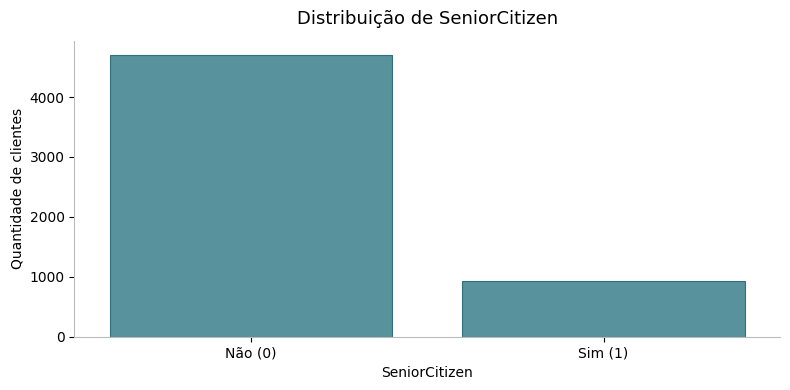

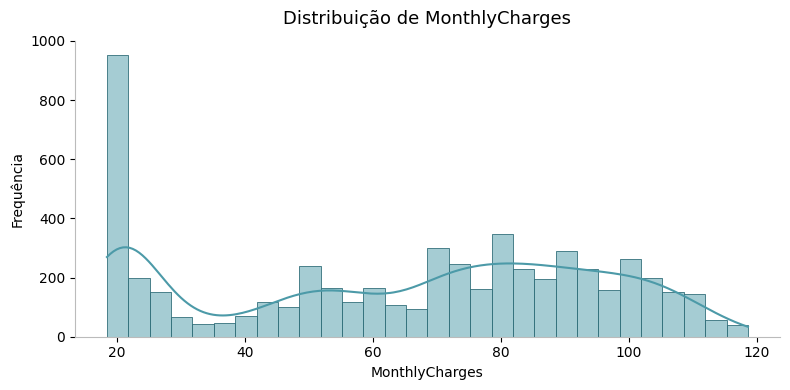

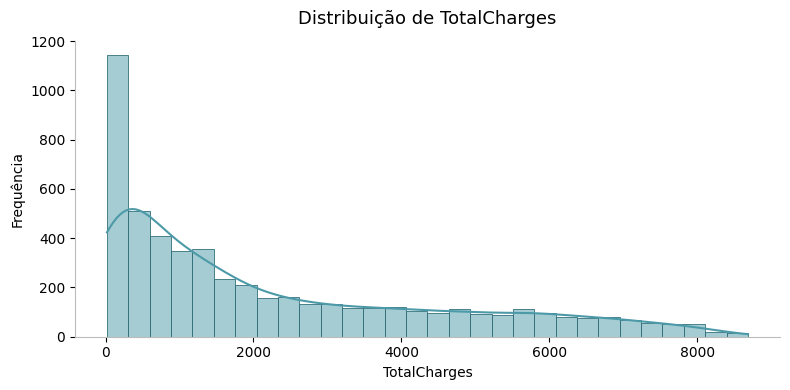

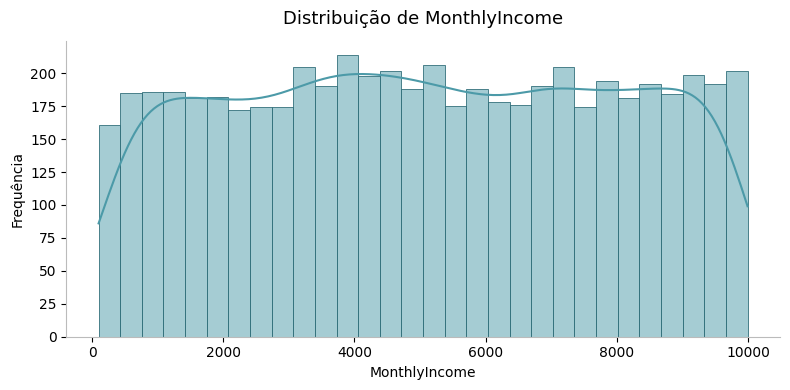

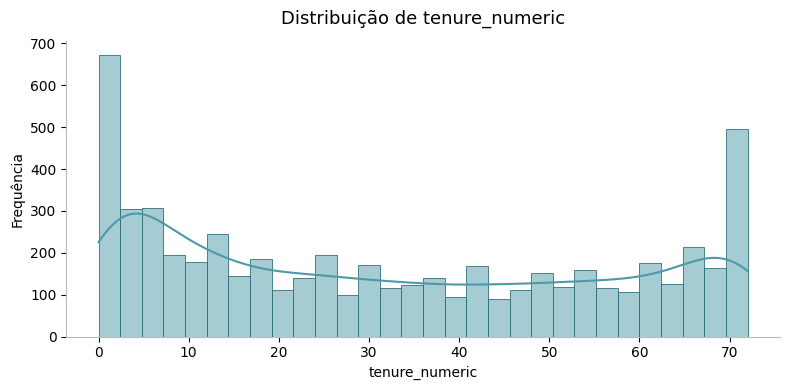

In [0]:
# Selecionar variáveis numéricas
numeric_cols = df_history_clean.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(8, 4))

    if col == "SeniorCitizen":
        # Gráfico de barras para variável binária
        counts = df_history_clean[col].value_counts().sort_index()

        sns.barplot(
            x=counts.index.astype(str),
            y=counts.values,
            color=cor_barras,
            edgecolor=cor_contorno,
            linewidth=0.8,
            ax=ax
        )

        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Não (0)", "Sim (1)"])
        ylabel = "Quantidade de clientes"

    else:
        # Histograma para variáveis numéricas contínuas
        sns.histplot(
            data=df_history_clean,
            x=col,
            bins=30,
            kde=True,
            color=cor_barras,
            edgecolor=cor_contorno,
            linewidth=0.6,
            ax=ax
        )

        ylabel = "Frequência"

    # Aplicar configuração visual padronizada
    configurar_grafico(
        ax,
        titulo=f"Distribuição de {col}",
        xlabel=col,
        ylabel=ylabel
    )

    plt.tight_layout()
    plt.show()

### 1.5 Visualização da distribuição das variáveis

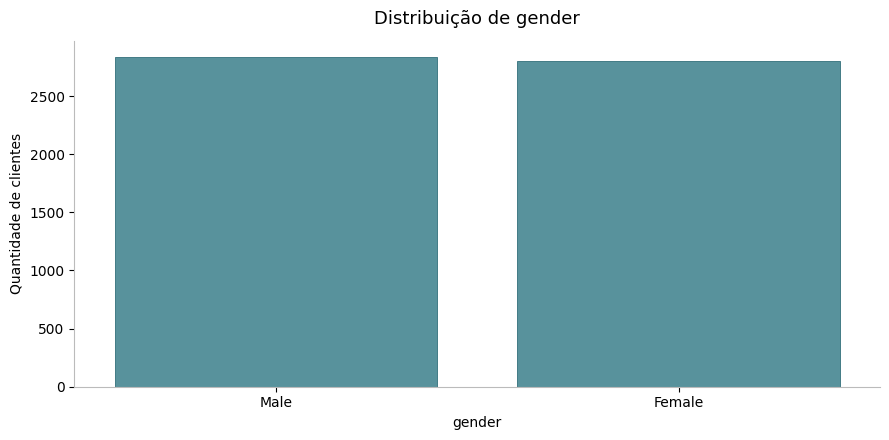

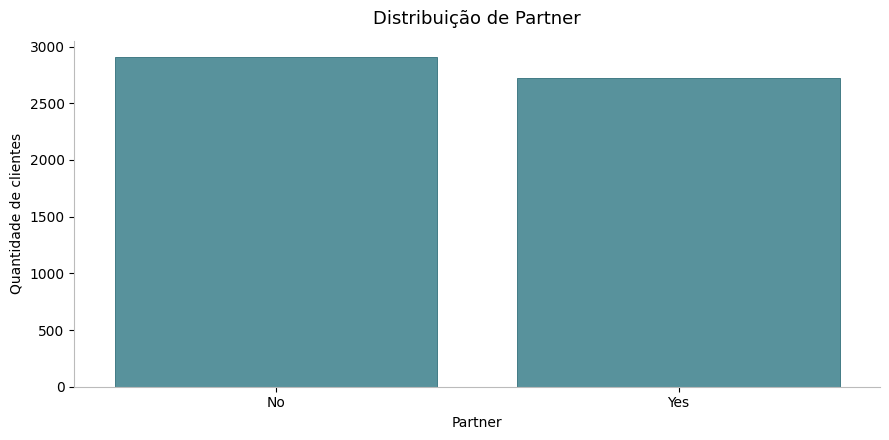

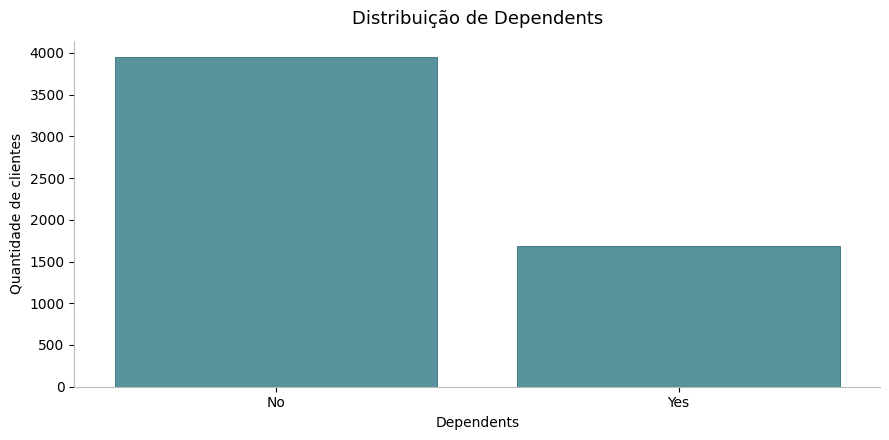

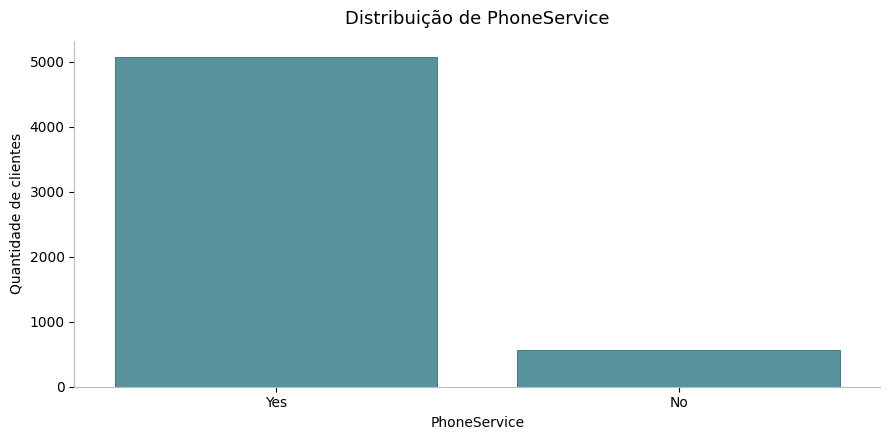

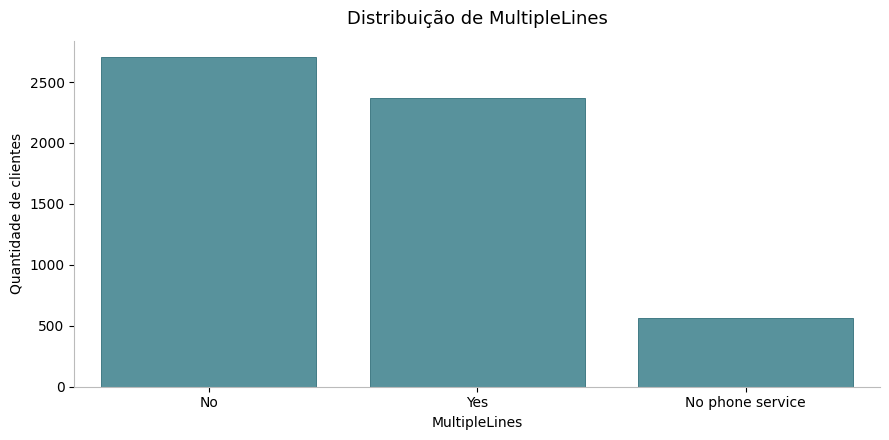

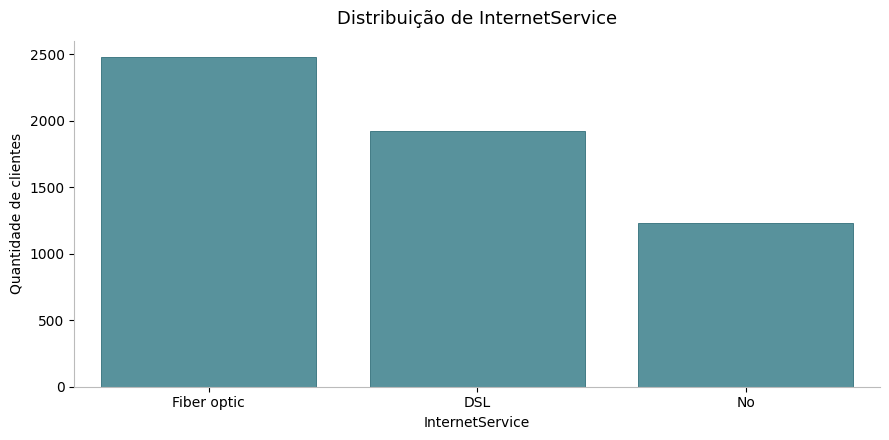

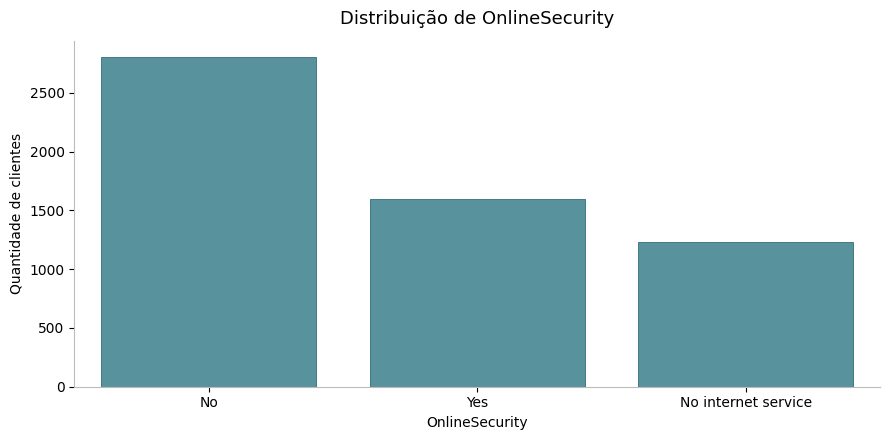

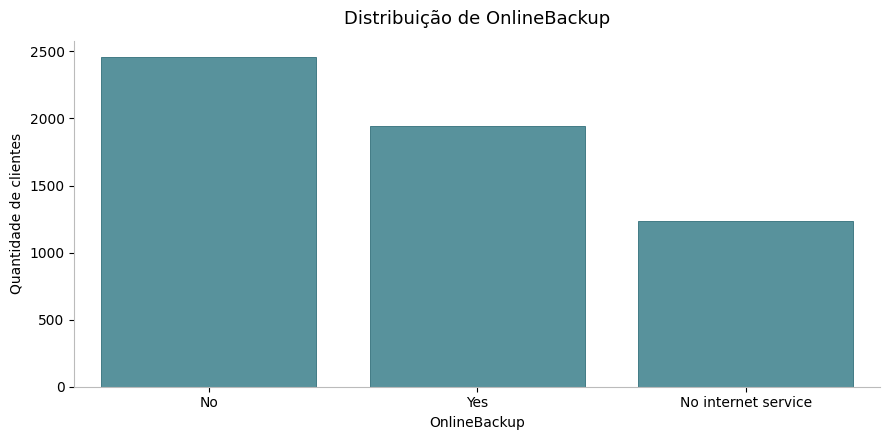

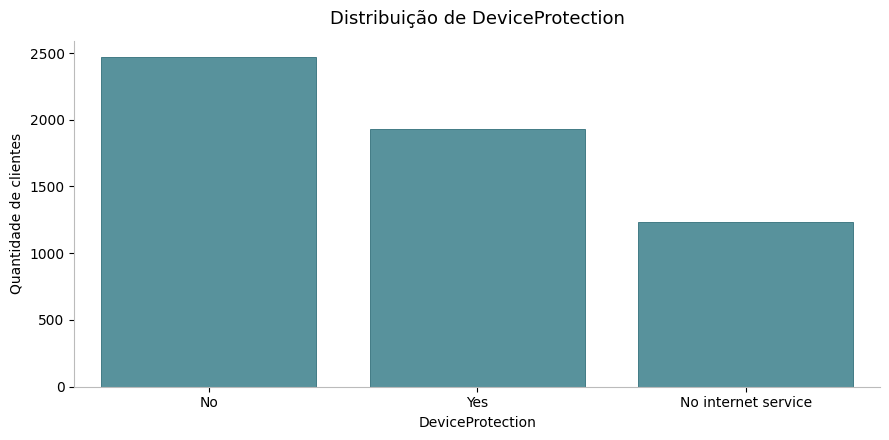

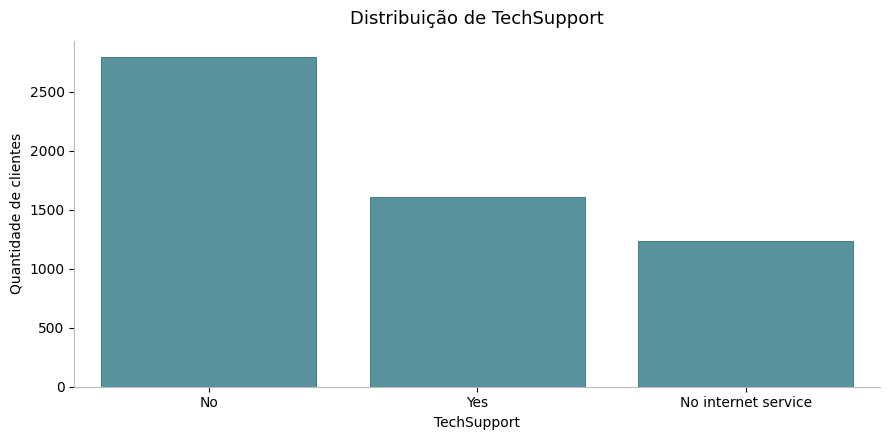

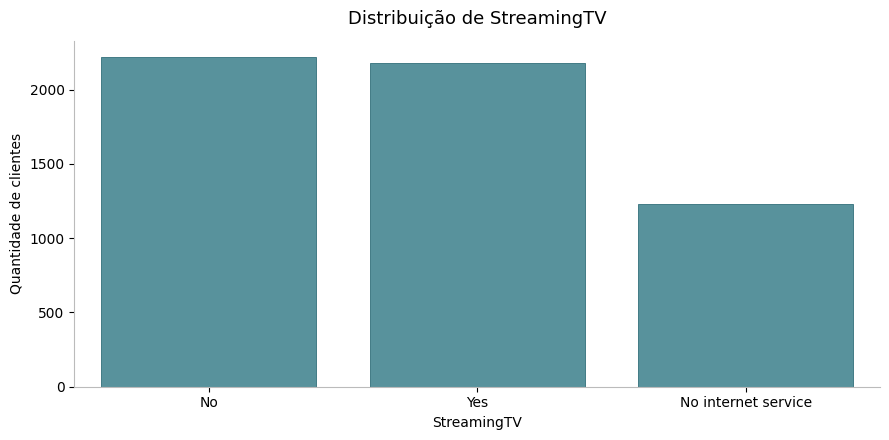

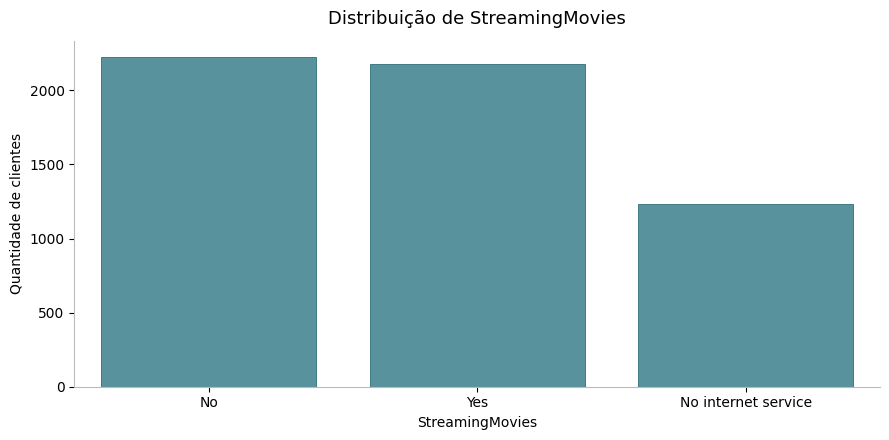

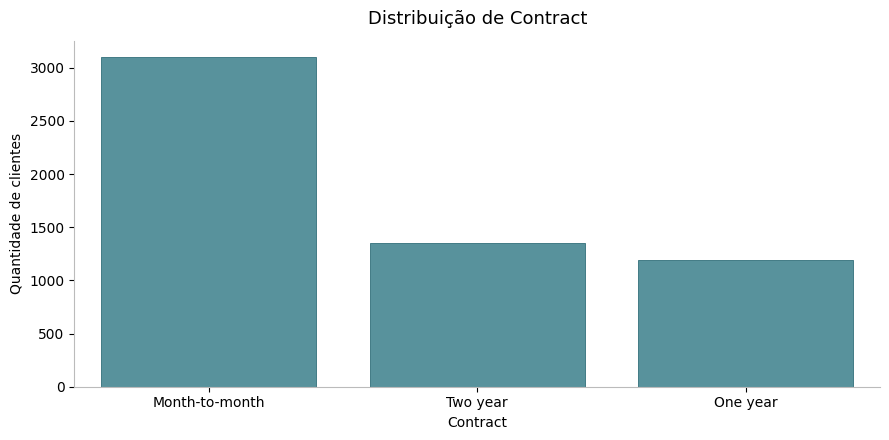

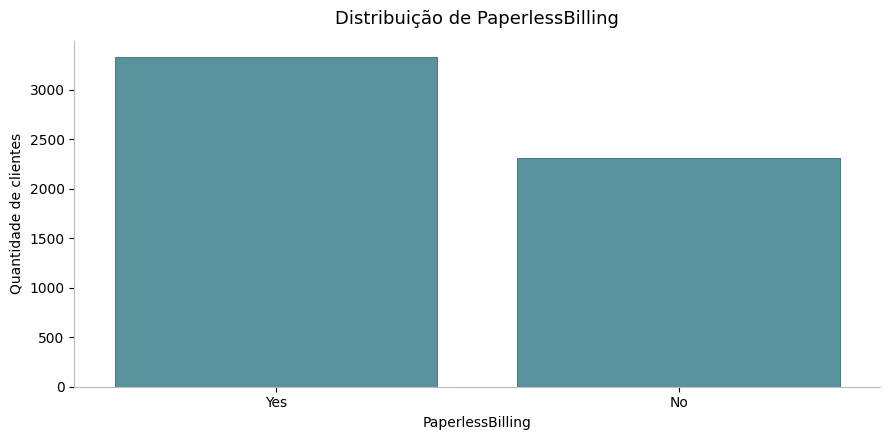

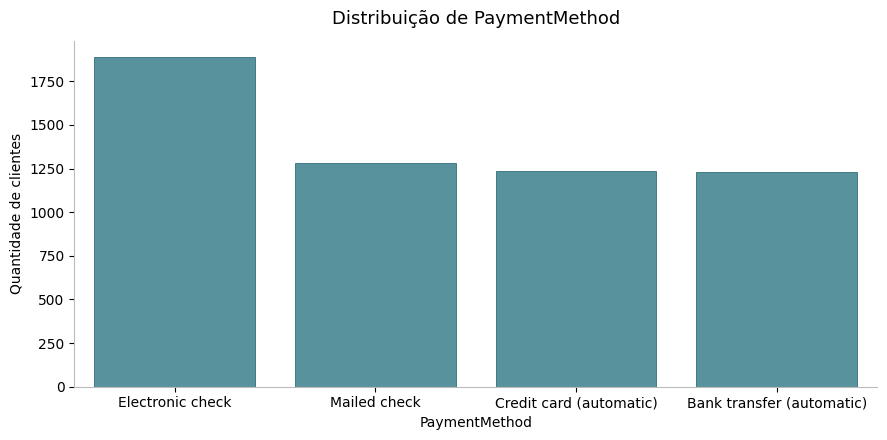

In [0]:
# Identificar variáveis categóricas
categorical_cols = df_history_clean.select_dtypes(
    include=["object", "string"]
).columns.tolist()

# Excluir identificadores, texto livre e variável alvo
excluded_cols = [
    "customerID",
    "CustomerFeedback",
    "Churn",
    "tenure"
]

categorical_cols = [
    col for col in categorical_cols
    if col not in excluded_cols
]

# Criar gráficos
for col in categorical_cols:

    counts = df_history_clean[col].value_counts(dropna=False)

    fig, ax = plt.subplots(figsize=(9, 4.5))

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        color=cor_barras,
        edgecolor=cor_contorno,
        linewidth=0.6,
        ax=ax
    )

    # Aplicar configuração visual padronizada
    configurar_grafico(
        ax,
        titulo=f"Distribuição de {col}",
        xlabel=col,
        ylabel="Quantidade de clientes"
    )

    plt.tight_layout()
    plt.show()

## 1.6 Análise da variável Churn
### 1.6.1. Distribuição de Churn

In [0]:
# Quantidade de clientes por categoria
churn_counts = df_history_clean["Churn"].value_counts()

# Percentual de clientes por categoria
churn_percent = (
    df_history_clean["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Consolidar resultados em uma tabela
churn_summary = pd.DataFrame({
    "Codificação": churn_counts.index.map({"No": 0, "Yes": 1}),
    "Quantidade": churn_counts,
    "Percentual (%)": churn_percent
})

print("=== DISTRIBUIÇÃO DE CHURN ===")
display(churn_summary)

=== DISTRIBUIÇÃO DE CHURN ===


Codificação,Quantidade,Percentual (%)
0,4130,73.3
1,1504,26.7


### 1.6.2. Visualização da distribuição de Churn

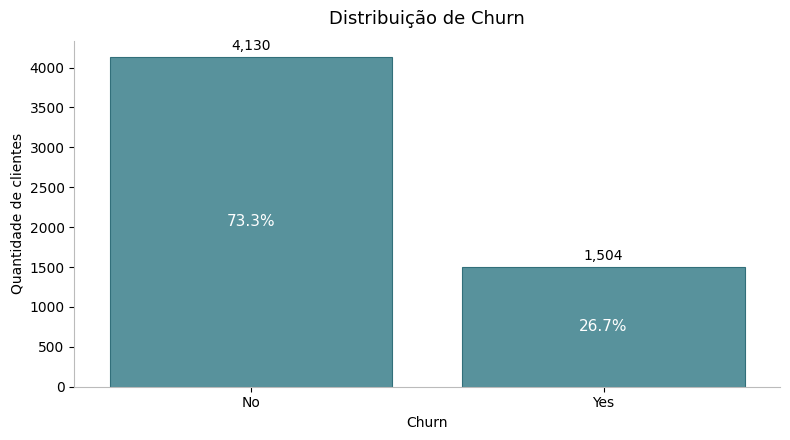

In [0]:
# Criar gráfico
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    color=cor_barras,
    edgecolor=cor_contorno,
    linewidth=0.8,
    ax=ax
)

# Exibir quantidade acima das barras e percentual dentro delas
for i, categoria in enumerate(churn_counts.index):

    # Quantidade acima da barra
    ax.text(
        i,
        churn_counts.values[i] + 50,
        f"{churn_counts.values[i]:,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

    # Percentual dentro da barra
    ax.text(
        i,
        churn_counts.values[i] * 0.5,
        f"{churn_percent[categoria]}%",
        ha="center",
        va="center",
        fontsize=11,
        color="white"
    )

# Aplicar configuração visual padronizada
configurar_grafico(
    ax,
    titulo="Distribuição de Churn",
    xlabel="Churn",
    ylabel="Quantidade de clientes"
)

plt.tight_layout()
plt.show()

### 1.7 Conclusões da análise de qualidade dos dados

A análise exploratória, complementada pelas informações fornecidas pelo negócio, identificou os seguintes pontos:

**1. Valores ausentes e desconhecidos**
- `TotalCharges` apresenta 278 valores ausentes no `history.csv`, correspondentes a aproximadamente 4,9% dos registros. Segundo o negócio, esses valores decorrem de problemas na base de dados de origem.
- `tenure` apresenta 19 valores `unknown` no `history.csv`. Esses registros foram preservados na coluna original e representados como valores ausentes (`NaN`) na coluna `tenure_numeric`. 
- Os valores ausentes de `TotalCharges` e `unknown` em `tenure` exigem uma estratégia de tratamento antes da modelagem.

**2. Inconsistências nas categorias**
- `PhoneService` apresenta inconsistência de capitalização (`Yes`/`yes` e `No`/`no`). Os valores foram padronizados no dataset df_history_clean.
- As demais variáveis categóricas apresentam domínios compatíveis com as informações fornecidas pelo negócio.

**3. Consistência entre variáveis de serviços**
- `MultipleLines = No` indica que o cliente possui apenas uma linha telefônica, enquanto `No phone service` indica ausência de serviço telefônico.
- `No internet service` nas variáveis de serviços adicionais indica que o cliente não possui internet contratada com a Terra Signal. Esses serviços podem ser contratados separadamente, mas dependem da contratação de internet.
- Essas categorias representam situações válidas do negócio e não devem ser tratadas como valores ausentes.

**4. Integridade dos registros**
- Não foram identificadas linhas completamente duplicadas.
- Não foram encontrados `customerID` duplicados, confirmando a unicidade dos identificadores no conjunto analisado.

**5. Tipos de dados**
- `tenure` está armazenada como texto (`object`), embora represente o tempo de relacionamento do cliente em meses. Foi criada a coluna `tenure_numeric` em formato numérico, preservando-se a coluna original `tenure` com os valores `unknown` intactos.
- `MonthlyCharges`, `TotalCharges` e `MonthlyIncome` já estão armazenadas em formatos numéricos.
- `SeniorCitizen` é uma variável binária codificada como 0 e 1, representando uma característica categórica do cliente.

**6. Considerações sobre a variável-alvo e possíveis variáveis explicativas**
- Segundo o negócio, `Churn = Yes` representa clientes cujo contrato foi definitivamente cancelado na data de corte da base, enquanto `Churn = No` representa clientes ativos nessa mesma data.
- O churn é, portanto, uma condição observada em um momento específico, e não um histórico permanente do cliente.
- `CustomerFeedback` merece atenção especial: a pesquisa de satisfação ocorre após a alta de cancelamentos, mas não há informação precisa sobre a data de coleta em relação ao cancelamento e a eventuais recontratações. Seu uso como variável preditora pode introduzir vazamento de informação (*data leakage*), devendo ser investigado antes de incluí-la no modelo.

**Conclusão geral**

O conjunto de dados apresenta identificadores únicos e domínios categóricos compatíveis com as definições fornecidas pelo negócio. Entretanto, foram identificados valores ausentes em `TotalCharges`, valores desconhecidos em `tenure`, inconsistência de capitalização em `PhoneService` e uma questão temporal relevante envolvendo `CustomerFeedback`.

Esses pontos deverão ser considerados na preparação dos dados e na seleção das variáveis para modelagem. As decisões de tratamento deverão ser documentadas e aplicadas de maneira consistente aos conjuntos de treinamento e inferência.


## 1.8 Complemento do EDA para modelagem
Nesta seção, investigamos a relação entre cada variável explicativa e a variável-alvo Churn, tanto para variáveis categóricas quanto numéricas. O objetivo é identificar quais características diferenciam clientes que cancelaram dos que permaneceram ativos.

### 1.8.1 Variáveis categóricas

In [0]:
def analisar_categorica_churn(coluna):

    # Tabela cruzada
    cruzamento = pd.crosstab(
        df_history_clean[coluna],
        df_history_clean["Churn"]
    ).reindex(columns=["No", "Yes"], fill_value=0)

    # Resumo dos resultados
    resumo = pd.DataFrame({
        coluna: cruzamento.index,
        "Total de clientes": cruzamento.sum(axis=1).values,
        "Clientes que cancelaram": cruzamento["Yes"].values,
        "Taxa de churn (%)": (
            cruzamento["Yes"] /
            cruzamento.sum(axis=1) * 100
        ).round(2).values
    })

    print(f"=== RELAÇÃO ENTRE {coluna.upper()} E CHURN ===")
    display(resumo)

    # Gráfico
    fig, ax = plt.subplots(figsize=(9, 4.5))

    sns.barplot(
        x=resumo[coluna],
        y=resumo["Taxa de churn (%)"],
        color=cor_barras,
        edgecolor=cor_contorno,
        linewidth=0.8,
        ax=ax
    )

    for i, percentual in enumerate(resumo["Taxa de churn (%)"]):
        ax.text(
            i, percentual * 0.5,
            f"{percentual:.1f}%",
            ha="center",
            va="center",
            fontsize=11,
            color="white"
        )

    configurar_grafico(
        ax,
        titulo=f"Taxa de Churn por {coluna}",
        xlabel=coluna,
        ylabel="Taxa de churn (%)"
    )

    plt.tight_layout()
    plt.show()

=== RELAÇÃO ENTRE CONTRACT E CHURN ===


Contract,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
Month-to-month,3099,1322,42.66
One year,1188,138,11.62
Two year,1347,44,3.27


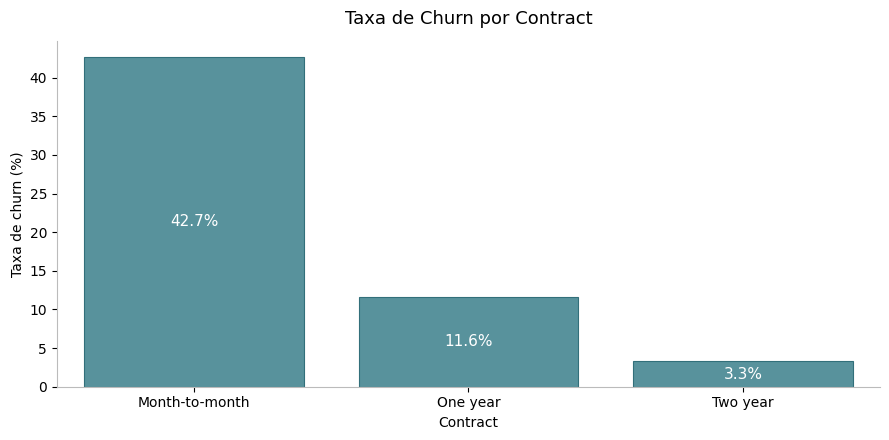

=== RELAÇÃO ENTRE INTERNETSERVICE E CHURN ===


InternetService,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
DSL,1924,373,19.39
Fiber optic,2477,1042,42.07
No,1233,89,7.22


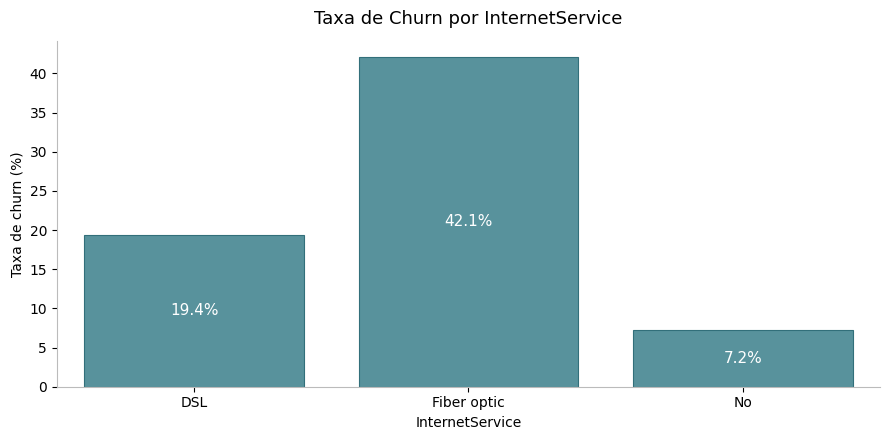

=== RELAÇÃO ENTRE PAYMENTMETHOD E CHURN ===


PaymentMethod,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
Bank transfer (automatic),1229,211,17.17
Credit card (automatic),1234,192,15.56
Electronic check,1888,852,45.13
Mailed check,1283,249,19.41


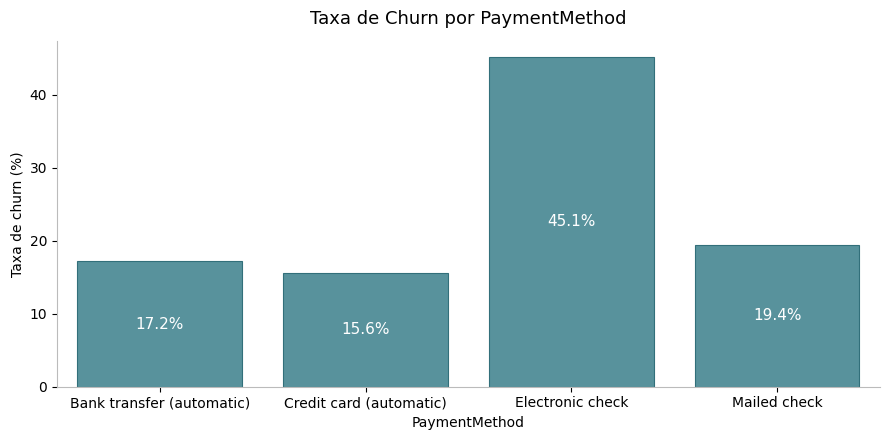

=== RELAÇÃO ENTRE ONLINESECURITY E CHURN ===


OnlineSecurity,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2803,1175,41.92
No internet service,1233,89,7.22
Yes,1598,240,15.02


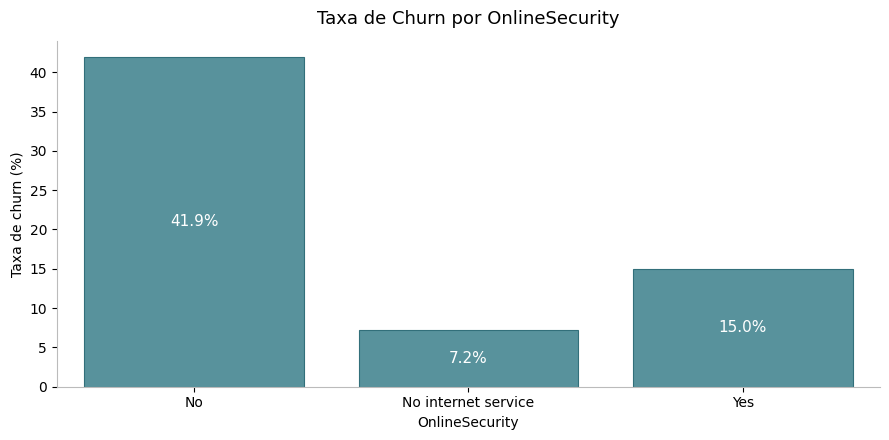

=== RELAÇÃO ENTRE ONLINEBACKUP E CHURN ===


OnlineBackup,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2457,981,39.93
No internet service,1233,89,7.22
Yes,1944,434,22.33


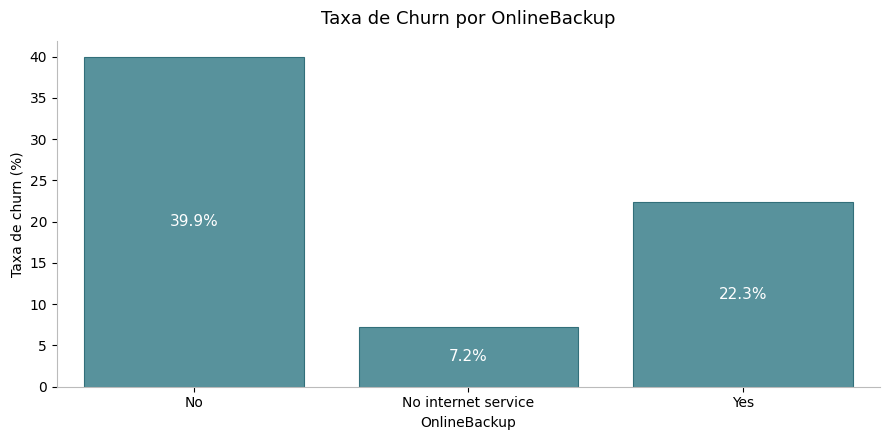

=== RELAÇÃO ENTRE DEVICEPROTECTION E CHURN ===


DeviceProtection,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2469,963,39.0
No internet service,1233,89,7.22
Yes,1932,452,23.4


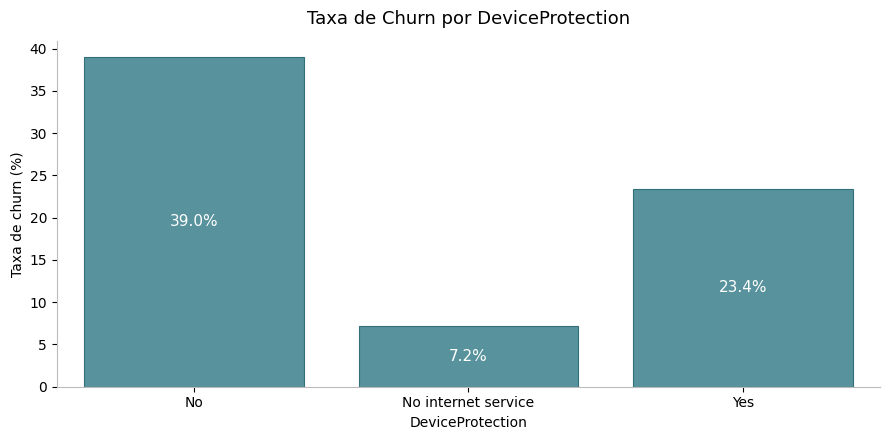

=== RELAÇÃO ENTRE TECHSUPPORT E CHURN ===


TechSupport,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2791,1168,41.85
No internet service,1233,89,7.22
Yes,1610,247,15.34


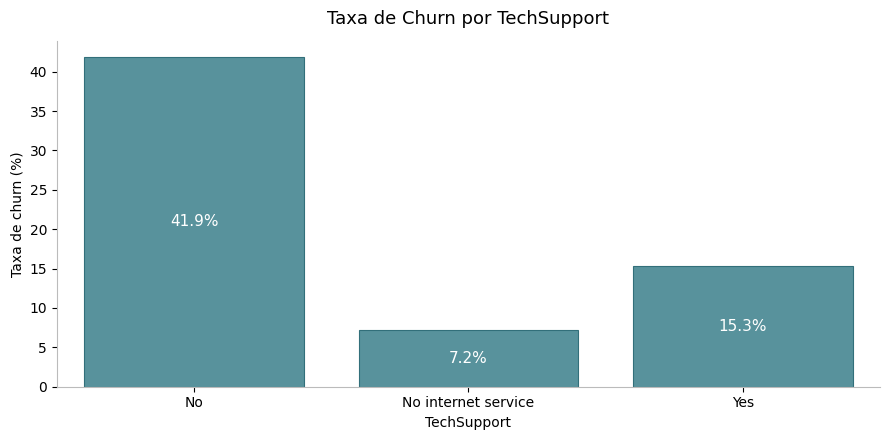

=== RELAÇÃO ENTRE SENIORCITIZEN E CHURN ===


SeniorCitizen,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
0,4706,1111,23.61
1,928,393,42.35


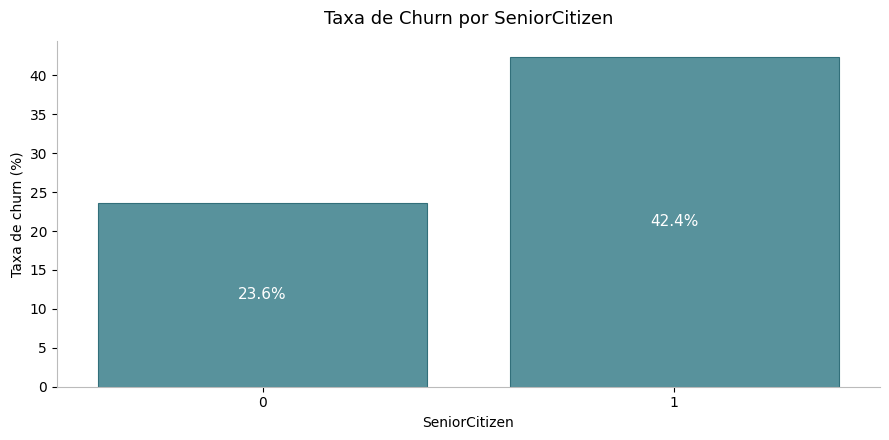

=== RELAÇÃO ENTRE PAPERLESSBILLING E CHURN ===


PaperlessBilling,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2307,383,16.6
Yes,3327,1121,33.69


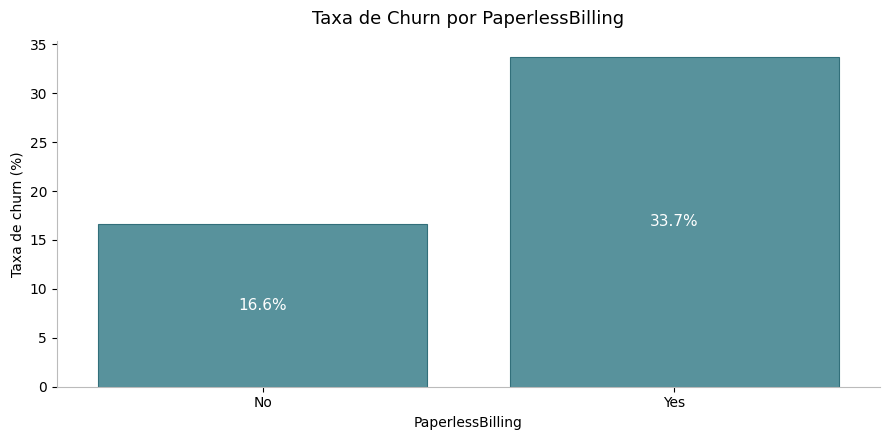

=== RELAÇÃO ENTRE PARTNER E CHURN ===


Partner,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2907,956,32.89
Yes,2727,548,20.1


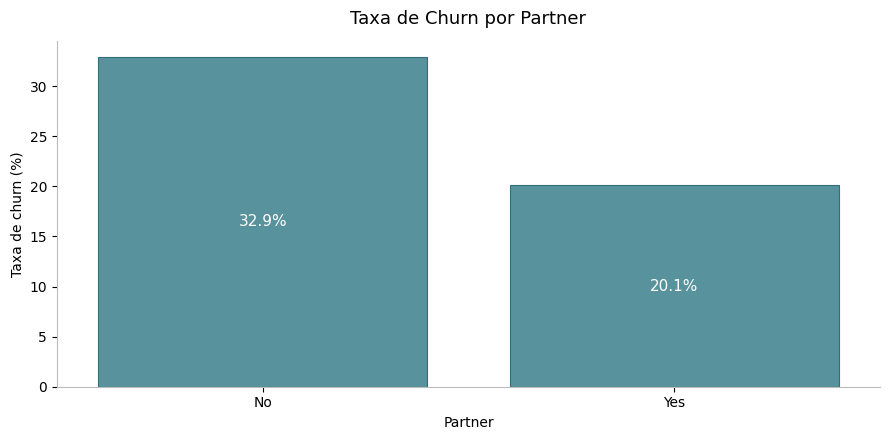

=== RELAÇÃO ENTRE DEPENDENTS E CHURN ===


Dependents,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,3949,1246,31.55
Yes,1685,258,15.31


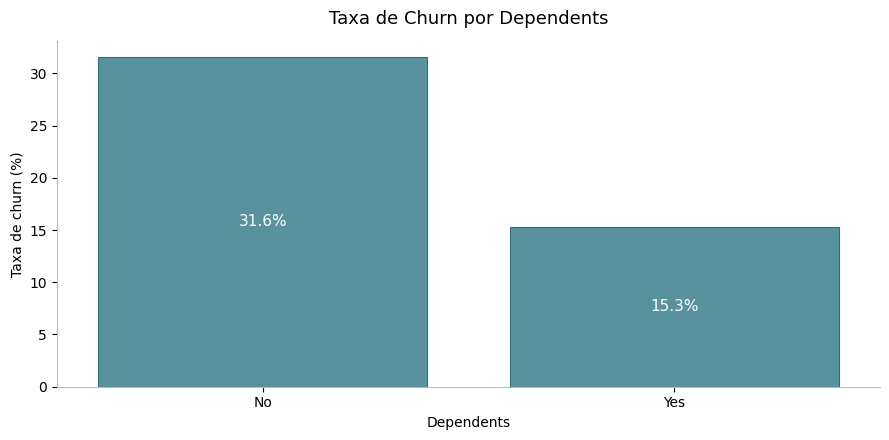

=== RELAÇÃO ENTRE MULTIPLELINES E CHURN ===


MultipleLines,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2704,674,24.93
No phone service,563,143,25.4
Yes,2367,687,29.02


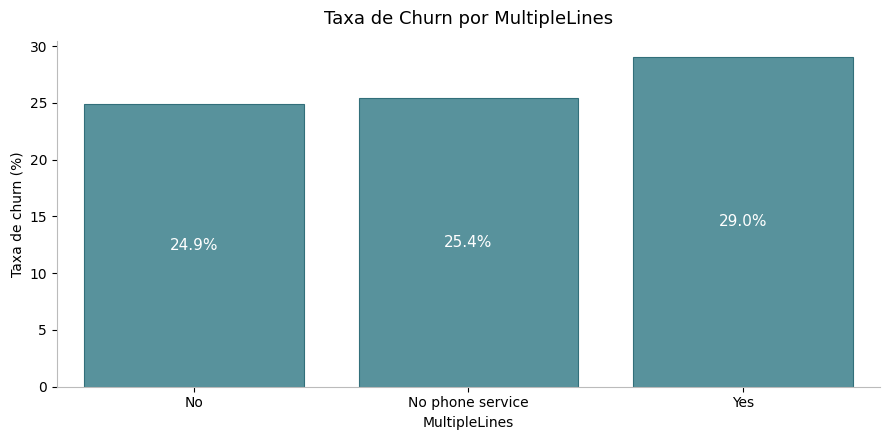

=== RELAÇÃO ENTRE STREAMINGTV E CHURN ===


StreamingTV,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2219,736,33.17
No internet service,1233,89,7.22
Yes,2182,679,31.12


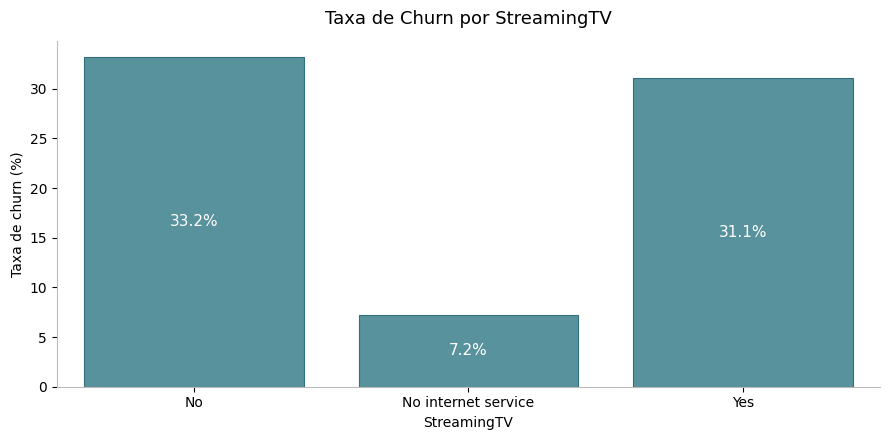

=== RELAÇÃO ENTRE STREAMINGMOVIES E CHURN ===


StreamingMovies,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,2224,757,34.04
No internet service,1233,89,7.22
Yes,2177,658,30.23


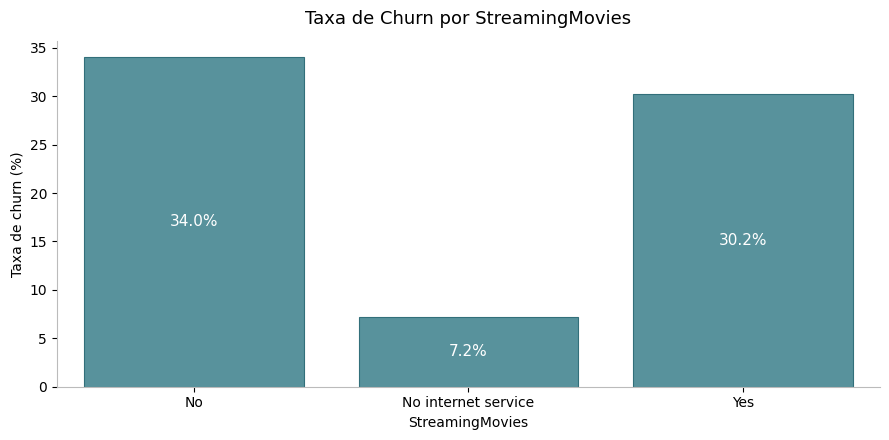

=== RELAÇÃO ENTRE GENDER E CHURN ===


gender,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
Female,2799,761,27.19
Male,2835,743,26.21


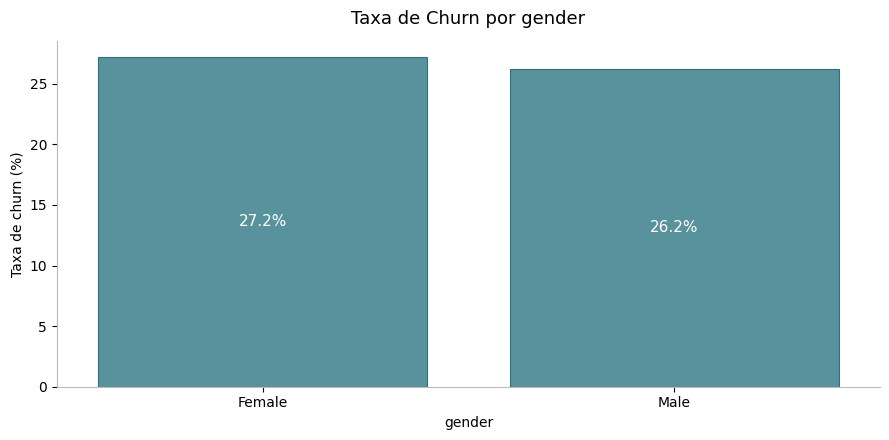

=== RELAÇÃO ENTRE PHONESERVICE E CHURN ===


PhoneService,Total de clientes,Clientes que cancelaram,Taxa de churn (%)
No,563,143,25.4
Yes,5071,1361,26.84


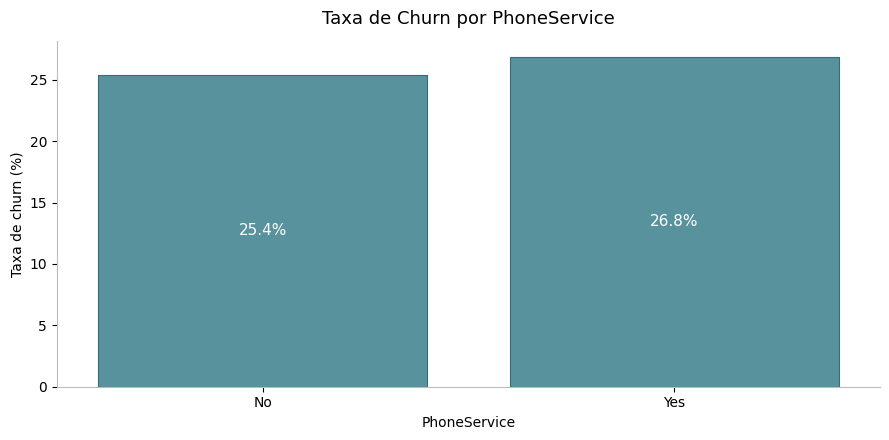

In [0]:
# Todas as variáveis categóricas para análise em relação ao Churn

categoricas = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "SeniorCitizen",
    "PaperlessBilling",
    "Partner",
    "Dependents",
    "MultipleLines",
    "StreamingTV",
    "StreamingMovies",
    "gender",
    "PhoneService"
]

# Executar análise para todas as variáveis
for coluna in categoricas:
    analisar_categorica_churn(coluna)


### 1.8.2 Variáveis numéricas

In [0]:
def analisar_numerica_churn(coluna):

    # Estatísticas descritivas por grupo de Churn
    resumo = (
        df_history_clean
        .groupby("Churn")[coluna]
        .agg(
            Quantidade="count",
            Media="mean",
            Mediana="median",
            Desvio_padrao="std",
            Minimo="min",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75),
            Maximo="max"
        )
        .round(2)
        .reset_index()
    )

    print(f"=== RELAÇÃO ENTRE {coluna.upper()} E CHURN ===")
    display(resumo)

    # Boxplot
    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.boxplot(
        data=df_history_clean,
        x="Churn",
        y=coluna,
        color=cor_barras,
        width=0.5,
        fliersize=3,
        linewidth=1,
        ax=ax
    )

    configurar_grafico(
        ax,
        titulo=f"Distribuição de {coluna} por Churn",
        xlabel="Churn",
        ylabel=coluna
    )

    plt.tight_layout()
    plt.show()


=== RELAÇÃO ENTRE TENURE_NUMERIC E CHURN ===


Churn,Quantidade,Media,Mediana,Desvio_padrao,Minimo,Q1,Q3,Maximo
No,4119,37.38,37.0,24.09,0.0,14.0,61.0,72.0
Yes,1496,18.33,10.0,19.65,1.0,2.0,30.0,72.0


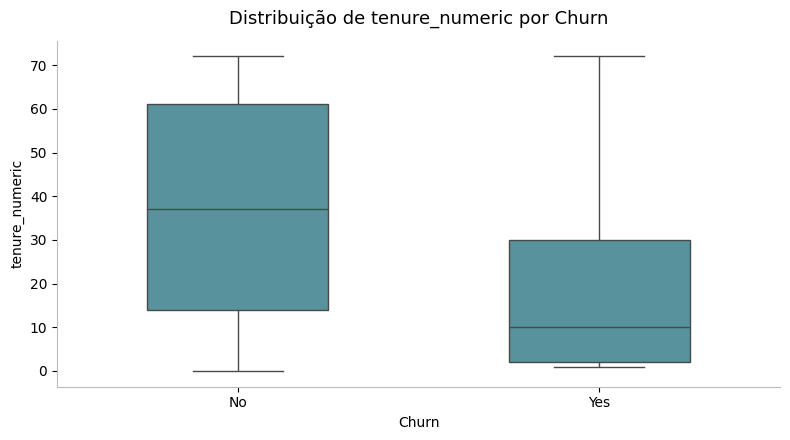

=== RELAÇÃO ENTRE MONTHLYCHARGES E CHURN ===


Churn,Quantidade,Media,Mediana,Desvio_padrao,Minimo,Q1,Q3,Maximo
No,4130,60.96,64.35,31.09,18.4,25.0,87.29,118.65
Yes,1504,74.63,79.82,24.81,18.85,55.9,94.4,118.35


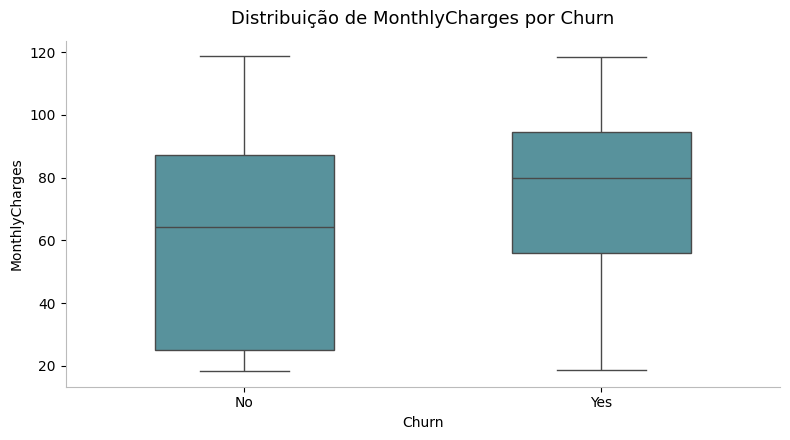

=== RELAÇÃO ENTRE TOTALCHARGES E CHURN ===


Churn,Quantidade,Media,Mediana,Desvio_padrao,Minimo,Q1,Q3,Maximo
No,3944,2525.88,1672.25,2313.78,18.8,573.0,4190.14,8670.1
Yes,1412,1562.42,753.15,1906.15,18.85,142.14,2385.05,8684.8


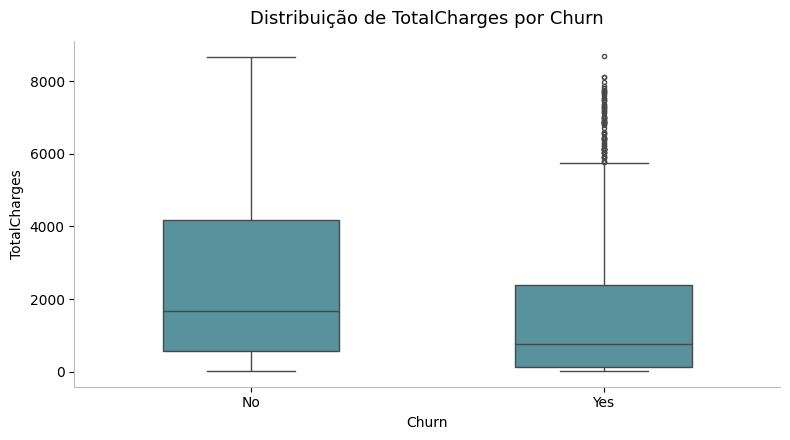

=== RELAÇÃO ENTRE MONTHLYINCOME E CHURN ===


Churn,Quantidade,Media,Mediana,Desvio_padrao,Minimo,Q1,Q3,Maximo
No,4130,5082.03,5048.0,2842.98,100,2672.5,7573.75,9993
Yes,1504,5167.63,5214.5,2828.91,102,2806.75,7584.25,9987


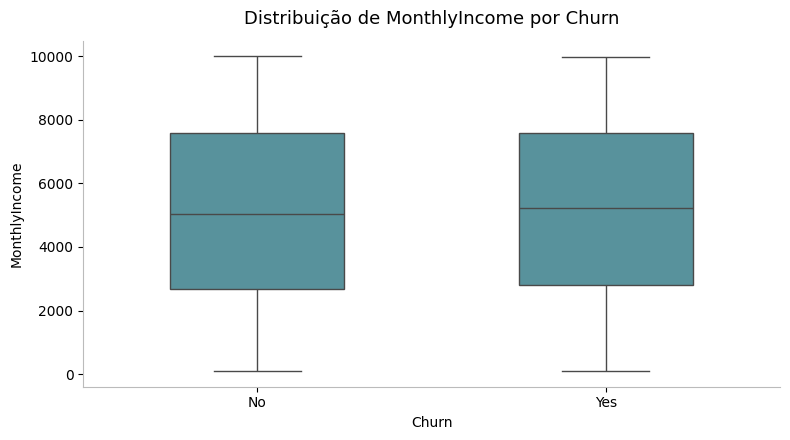

In [0]:
# Variáveis numéricas para análise em relação ao Churn

numericas = [
    "tenure_numeric",
    "MonthlyCharges",
    "TotalCharges",
    "MonthlyIncome"
]

# Executar análise para todas as variáveis
for coluna in numericas:
    analisar_numerica_churn(coluna)



### 1.8.3 Estatísticas descritivas das variáveis numéricas

Investigamos `tenure_numeric`, `MonthlyCharges`, `TotalCharges` e `MonthlyIncome`, incluindo medidas de assimetria, quantis e outliers pelo método IQR.

In [0]:
# ============================================================
# 1.9.1a Estatísticas descritivas, assimetria, curtose e outliers
# ============================================================

numericas = ["tenure_numeric", "MonthlyCharges", "TotalCharges", "MonthlyIncome"]

# Estatísticas descritivas expandidas
estatisticas = df_history_clean[numericas].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

estatisticas["skewness"] = df_history_clean[numericas].skew()
estatisticas["kurtosis"] = df_history_clean[numericas].kurtosis()

print("=== ESTATÍSTICAS DESCRITIVAS, ASSIMETRIA E CURTOSE ===")
display(estatisticas.round(2).reset_index().rename(columns={"index": "Variável"}))

# Outliers pelo método IQR
outliers_summary = []
for col in numericas:
    s = df_history_clean[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((s < lower) | (s > upper)).sum()

    outliers_summary.append({
        "Variável": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Limite inferior": round(lower, 2),
        "Limite superior": round(upper, 2),
        "Outliers (IQR)": n_outliers,
        "% do total": round(100 * n_outliers / len(s), 2)
    })

outliers_df = pd.DataFrame(outliers_summary)
print("\n=== OUTLIERS PELO MÉTODO IQR ===")
display(outliers_df)


=== ESTATÍSTICAS DESCRITIVAS, ASSIMETRIA E CURTOSE ===


Variável,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
tenure_numeric,5615.0,32.31,24.48,0.0,1.0,1.0,9.0,29.0,55.0,71.0,72.0,72.0,0.24,-1.39
MonthlyCharges,5634.0,64.61,30.15,18.4,19.2,19.65,35.16,70.3,89.8,107.4,114.6,118.65,-0.21,-1.27
TotalCharges,5356.0,2271.88,2253.78,18.8,19.9,50.14,412.9,1390.72,3729.75,6889.85,7985.7,8684.8,0.97,-0.22
MonthlyIncome,5634.0,5104.88,2839.23,100.0,222.65,646.65,2693.75,5079.5,7574.75,9541.35,9887.67,9993.0,-0.01,-1.18



=== OUTLIERS PELO MÉTODO IQR ===


Variável,Q1,Q3,IQR,Limite inferior,Limite superior,Outliers (IQR),% do total
tenure_numeric,9.0,55.0,46.0,-60.0,124.0,0,0.0
MonthlyCharges,35.16,89.8,54.64,-46.79,171.76,0,0.0
TotalCharges,412.9,3729.75,3316.85,-4562.38,8705.02,0,0.0
MonthlyIncome,2693.75,7574.75,4881.0,-4627.75,14896.25,0,0.0


### 1.8.4 Matrizes de correlação

=== CORRELAÇÃO DE PEARSON ===


tenure_numeric,MonthlyCharges,TotalCharges,MonthlyIncome
1.0,0.25,0.82,-0.0
0.25,1.0,0.65,0.01
0.82,0.65,1.0,0.01
-0.0,0.01,0.01,1.0


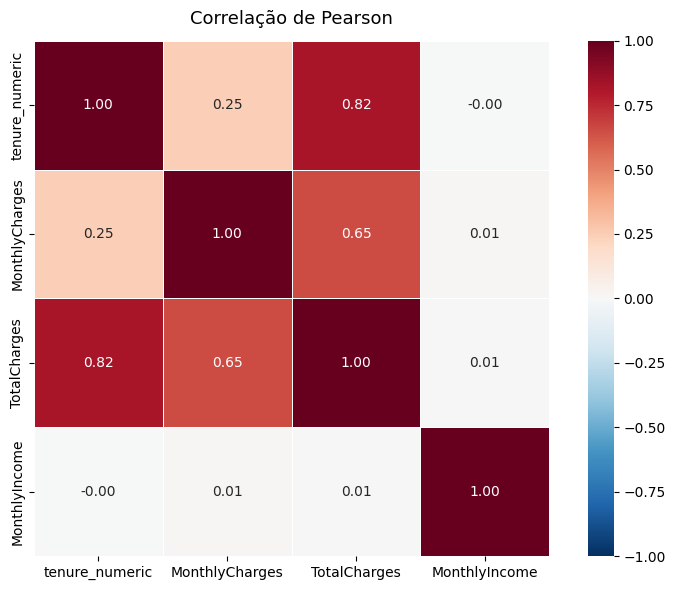


=== CORRELAÇÃO DE SPEARMAN ===


tenure_numeric,MonthlyCharges,TotalCharges,MonthlyIncome
1.0,0.28,0.89,-0.0
0.28,1.0,0.64,0.01
0.89,0.64,1.0,0.01
-0.0,0.01,0.01,1.0


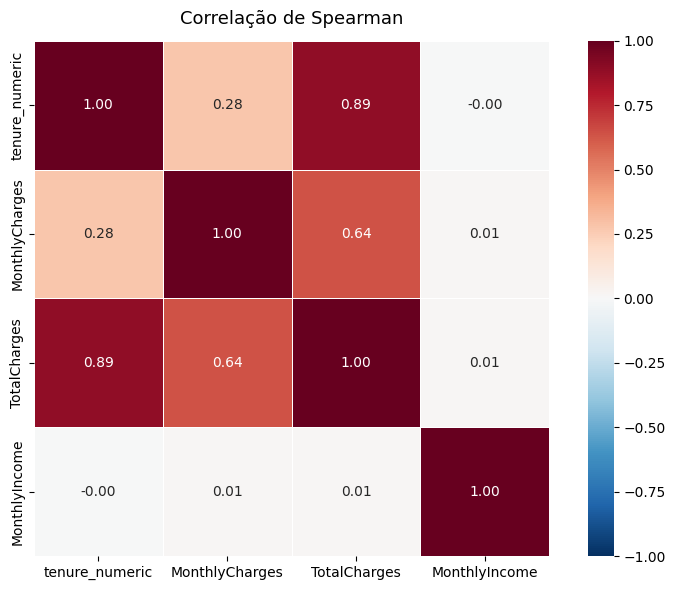

In [0]:
# ============================================================
# 1.9.2a Matrizes de correlação entre variáveis numéricas
# ============================================================

numericas_com_tenure = ["tenure_numeric", "MonthlyCharges", "TotalCharges", "MonthlyIncome"]

# Correlação de Pearson
print("=== CORRELAÇÃO DE PEARSON ===")
corr_pearson = df_history_clean[numericas_com_tenure].corr(method="pearson")
display(corr_pearson.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax
)
configurar_grafico(ax, titulo="Correlação de Pearson", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

# Correlação de Spearman
print("\n=== CORRELAÇÃO DE SPEARMAN ===")
corr_spearman = df_history_clean[numericas_com_tenure].corr(method="spearman")
display(corr_spearman.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax
)
configurar_grafico(ax, titulo="Correlação de Spearman", xlabel="", ylabel="")
plt.tight_layout()
plt.show()


=== COMPARAÇÃO: TotalCharges vs MonthlyCharges × tenure ===
Registros com ambos os valores: 5338

Estatísticas da diferença (TotalCharges - MonthlyCharges × tenure):


count,mean,std,min,25%,50%,75%,max
5338.0,0.36,66.57,-360.65,-28.15,0.0,28.7,373.25



Estatísticas da diferença relativa:


count,mean,std,min,25%,50%,75%,max
5338.0,0.0321,0.0396,0.0,0.0072,0.02,0.0418,0.4949


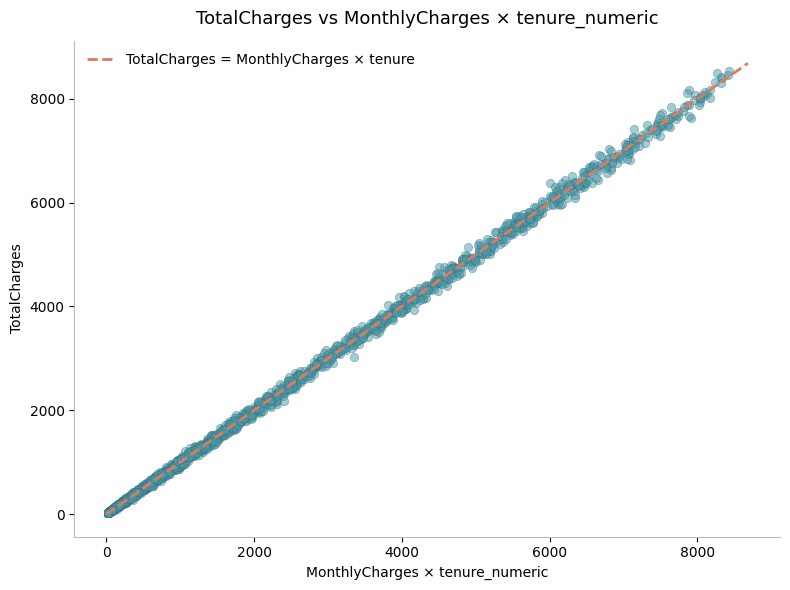

In [0]:
# ============================================================
# Relação entre TotalCharges, MonthlyCharges e tenure_numeric
# ============================================================

df_temp = df_history_clean.copy()
df_temp["MonthlyCharges_x_tenure"] = df_temp["MonthlyCharges"] * df_temp["tenure_numeric"]

# Comparação entre TotalCharges e MonthlyCharges * tenure
comparacao = df_temp[["TotalCharges", "MonthlyCharges_x_tenure"]].dropna()
comparacao["diferenca"] = comparacao["TotalCharges"] - comparacao["MonthlyCharges_x_tenure"]
comparacao["diferenca_abs"] = comparacao["diferenca"].abs()
comparacao["diferenca_relativa"] = comparacao["diferenca_abs"] / comparacao["MonthlyCharges_x_tenure"].replace(0, np.nan)

print("=== COMPARAÇÃO: TotalCharges vs MonthlyCharges × tenure ===")
print(f"Registros com ambos os valores: {len(comparacao)}")
print("\nEstatísticas da diferença (TotalCharges - MonthlyCharges × tenure):")
display(comparacao["diferenca"].describe().round(2).to_frame().T)
print("\nEstatísticas da diferença relativa:")
display(comparacao["diferenca_relativa"].describe().round(4).to_frame().T)

# Scatter plot com amostra para melhor legibilidade
fig, ax = plt.subplots(figsize=(8, 6))

amostra = comparacao.sample(min(2000, len(comparacao)), random_state=42)

sns.scatterplot(
    data=amostra,
    x="MonthlyCharges_x_tenure",
    y="TotalCharges",
    color=cor_barras,
    edgecolor=cor_contorno,
    alpha=0.5,
    ax=ax
)

# Linha de referência y = x
max_val = comparacao[["MonthlyCharges_x_tenure", "TotalCharges"]].max().max()
ax.plot(
    [0, max_val],
    [0, max_val],
    color="#E07A5F",
    linestyle="--",
    linewidth=2,
    label="TotalCharges = MonthlyCharges × tenure"
)

configurar_grafico(
    ax,
    titulo="TotalCharges vs MonthlyCharges × tenure_numeric",
    xlabel="MonthlyCharges × tenure_numeric",
    ylabel="TotalCharges"
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


### 1.8.5 Qualidade dos dados

In [0]:
# ============================================================
# Registros com tenure_numeric = 0
# ============================================================

registros_tenure_0 = df_history_clean[df_history_clean["tenure_numeric"] == 0]

print(f"=== REGISTROS COM tenure_numeric = 0 ===")
print(f"Quantidade: {len(registros_tenure_0)}")

if len(registros_tenure_0) > 0:
    print("\nDistribuição de Churn:")
    display(registros_tenure_0["Churn"].value_counts(dropna=False).to_frame("Quantidade"))

    print("\nEstatísticas das variáveis numéricas:")
    display(
    registros_tenure_0[["MonthlyCharges", "TotalCharges", "MonthlyIncome"]]
    .describe()
    .T
    .round(2)
    .rename_axis("Variável")
    .reset_index()
)

    print("\nAmostra dos registros:")
    display(
        registros_tenure_0[["customerID", "tenure_numeric", "MonthlyCharges", "TotalCharges", "Churn"]]
        .head(10)
        .round(2)
    )


=== REGISTROS COM tenure_numeric = 0 ===
Quantidade: 10

Distribuição de Churn:


Quantidade
10



Estatísticas das variáveis numéricas:


Variável,count,mean,std,min,25%,50%,75%,max
MonthlyCharges,10.0,37.48,21.0,19.7,20.06,25.55,55.18,73.35
TotalCharges,0.0,null,null,null,null,null,null,null
MonthlyIncome,10.0,6292.5,3302.54,1135.0,3005.75,7647.5,9018.0,9833.0



Amostra dos registros:


customerID,tenure_numeric,MonthlyCharges,TotalCharges,Churn
2520-SGTTA,0.0,20.0,null,No
2923-ARZLG,0.0,19.7,null,No
4472-LVYGI,0.0,52.55,null,No
1371-DWPAZ,0.0,56.05,null,No
3213-VVOLG,0.0,25.35,null,No
7644-OMVMY,0.0,19.85,null,No
3115-CZMZD,0.0,20.25,null,No
2775-SEFEE,0.0,61.9,null,No
4367-NUYAO,0.0,25.75,null,No
4075-WKNIU,0.0,73.35,null,No


In [0]:
# ============================================================
# Valores ausentes de TotalCharges
# ============================================================

missing_total = df_history_clean[df_history_clean["TotalCharges"].isna()]

print(f"=== REGISTROS COM TotalCharges AUSENTE ===")
print(f"Quantidade: {len(missing_total)}")
print(f"Percentual sobre a base: {100 * len(missing_total) / len(df_history_clean):.2f}%")

print("\nDistribuição de Churn:")
display(missing_total["Churn"].value_counts(dropna=False).to_frame("Quantidade"))

print("\nEstatísticas de tenure_numeric:")
display(missing_total["tenure_numeric"].describe().round(2).to_frame().T)

print("\nEstatísticas de MonthlyCharges:")
display(missing_total["MonthlyCharges"].describe().round(2).to_frame().T)

# Comparação com registros sem missing em TotalCharges
comparativo_missing = pd.DataFrame({
    "TotalCharges ausente": [
        missing_total["Churn"].map({"Yes": 1, "No": 0}).mean(),
        missing_total["tenure_numeric"].mean(),
        missing_total["MonthlyCharges"].mean()
    ],
    "TotalCharges preenchido": [
        df_history_clean.dropna(subset=["TotalCharges"])["Churn"].map({"Yes": 1, "No": 0}).mean(),
        df_history_clean.dropna(subset=["TotalCharges"])["tenure_numeric"].mean(),
        df_history_clean.dropna(subset=["TotalCharges"])["MonthlyCharges"].mean()
    ]
}, index=["Taxa de Churn", "Tenure médio", "MonthlyCharges médio"])

print("\n=== COMPARAÇÃO ENTRE REGISTROS COM E SEM TotalCharges ===")
display(comparativo_missing.round(2))


=== REGISTROS COM TotalCharges AUSENTE ===
Quantidade: 278
Percentual sobre a base: 4.93%

Distribuição de Churn:


Quantidade
186
92



Estatísticas de tenure_numeric:


count,mean,std,min,25%,50%,75%,max
277.0,29.7,24.78,0.0,5.0,25.0,54.0,72.0



Estatísticas de MonthlyCharges:


count,mean,std,min,25%,50%,75%,max
278.0,67.28,30.81,18.85,41.1,74.4,93.88,116.45



=== COMPARAÇÃO ENTRE REGISTROS COM E SEM TotalCharges ===


TotalCharges ausente,TotalCharges preenchido
0.33,0.26
29.7,32.44
67.28,64.47


In [0]:
# ============================================================
# Possíveis inconsistências entre variáveis numéricas
# ============================================================

df_temp = df_history_clean.copy()
df_temp["MonthlyCharges_x_tenure"] = df_temp["MonthlyCharges"] * df_temp["tenure_numeric"]
df_temp["diferenca"] = df_temp["TotalCharges"] - df_temp["MonthlyCharges_x_tenure"]
df_temp["diferenca_abs"] = df_temp["diferenca"].abs()
df_temp["diferenca_relativa"] = df_temp["diferenca_abs"] / df_temp["MonthlyCharges_x_tenure"].replace(0, np.nan)

# Critérios de investigação (não implicam exclusão)
limite_abs = 50
limite_rel = 0.20

base_valida = df_temp[df_temp["TotalCharges"].notna() & df_temp["tenure_numeric"].notna()]

discrepantes = base_valida[
    (base_valida["diferenca_abs"] > limite_abs) |
    (base_valida["diferenca_relativa"] > limite_rel)
]

print("=== POSSÍVEIS INCONSISTÊNCIAS ENTRE TotalCharges, MonthlyCharges E tenure_numeric ===")
print(f"Critério: |TotalCharges - MonthlyCharges × tenure| > R$ {limite_abs}")
print(f"           OU diferença relativa > {limite_rel * 100:.0f}%")
print(f"Registros discrepantes: {len(discrepantes)} ({100 * len(discrepantes) / len(base_valida):.2f}% dos registros com ambos os valores)")

if len(discrepantes) > 0:
    print("\nAmostra dos registros com maiores diferenças absolutas:")
    display(
        discrepantes
        .sort_values("diferenca_abs", ascending=False)
        [[
            "customerID", "tenure_numeric", "MonthlyCharges", "TotalCharges",
            "MonthlyCharges_x_tenure", "diferenca", "diferenca_relativa", "Churn"
        ]]
        .head(10)
        .round(2)
    )


=== POSSÍVEIS INCONSISTÊNCIAS ENTRE TotalCharges, MonthlyCharges E tenure_numeric ===
Critério: |TotalCharges - MonthlyCharges × tenure| > R$ 50
           OU diferença relativa > 20%
Registros discrepantes: 1777 (33.29% dos registros com ambos os valores)

Amostra dos registros com maiores diferenças absolutas:


customerID,tenure_numeric,MonthlyCharges,TotalCharges,MonthlyCharges_x_tenure,diferenca,diferenca_relativa,Churn
9350-VLHMB,67.0,89.55,6373.1,5999.85,373.25,0.06,No
0083-PIVIK,64.0,81.25,5567.55,5200.0,367.55,0.07,No
7182-OVLBJ,62.0,101.15,6638.35,6271.3,367.05,0.06,No
0266-CLZKZ,67.0,105.65,6717.9,7078.55,-360.65,0.05,No
1679-JRFBR,70.0,108.15,7930.55,7570.5,360.05,0.05,No
4612-THJBS,56.0,104.75,5510.65,5866.0,-355.35,0.06,Yes
7176-WRTNX,70.0,114.95,7711.25,8046.5,-335.25,0.04,No
4342-HFXWS,48.0,69.7,3023.65,3345.6,-321.95,0.1,No
8879-XUAHX,71.0,116.25,8564.75,8253.75,311.0,0.04,No
2386-OWURY,58.0,95.3,5817.7,5527.4,290.3,0.05,No


### 1.9 Principais resultados e considerações para a modelagem

A seguir, os principais achados deste complemento e os aspectos que devem ser considerados na preparação do modelo:

#### 1. Demais variáveis numéricas
- **`tenure_numeric`**: a análise da seção 1.8 mostrou que a taxa de churn diminui fortemente à medida que o tempo de relacionamento aumenta. Modelos baseados em árvores capturam bem esse padrão não linear.
- **`MonthlyCharges`**: distribuição com média de R$ 64,61 e dois picos visuais (clientes com serviço básico e clientes com serviços adicionais). Clientes que deram churn apresentam `MonthlyCharges` médio superior aos que permaneceram. Não foram detectados outliers pelo IQR.
- **`TotalCharges`**: distribuição assimétrica positiva (*skewness* aproximadamente 0,97). Está altamente correlacionada com `tenure` (Pearson aproximadamente 0,82; Spearman aproximadamente 0,89) e com `MonthlyCharges` (Pearson aproximadamente 0,65), indicando informação redundante se todas forem incluídas simultaneamente.
- **`MonthlyIncome`**: distribuição aproximadamente uniforme, sem correlação aparente com `Churn` nem com as demais variáveis numéricas. Sua origem ainda precisa ser confirmada pelo negócio.
- **`TotalCharges` vs `MonthlyCharges × tenure`**: a diferença entre as duas quantidades tem mediana próxima de zero, mas há discrepâncias consideráveis em parte dos registros. Isso pode refletir mudanças de plano, descontos, taxas ou impostos ao longo do tempo. Portanto, embora as variáveis sejam relacionadas, não são deterministicamente equivalentes.

#### 2. Qualidade dos dados
- **`tenure = 0`**: há 10 registros, todos com `Churn = No` e `TotalCharges` ausente. Tratam-se de clientes com relacionamento ainda não completado no primeiro mês.
- **`TotalCharges` ausente**: 278 registros (aproximadamente 4,9% da base). A taxa de churn nesse grupo é de aproximadamente 33%, superior aos 26% dos registros preenchidos. Além disso, o `tenure` médio é de cerca de 30 meses, ou seja, os missing **não estão concentrados em clientes novos**. Isso indica que o mecanismo de missing não é completamente aleatório e deve ser considerado na escolha da estratégia de tratamento.
- **Inconsistências numéricas**: uma parcela dos registros apresenta diferença absoluta superior a R$ 50 ou relativa superior a 20% entre `TotalCharges` e `MonthlyCharges × tenure`. Essas discrepâncias não são necessariamente erros, mas devem ser investigadas junto ao negócio antes da modelagem.

#### 3. Implicações para a modelagem
- **Redundância entre variáveis**: a alta correlação entre `TotalCharges`, `tenure` e `MonthlyCharges` sugere que `TotalCharges` pode ser removida sem perda significativa de informação, já que é aproximadamente `tenure × MonthlyCharges`. Na etapa de modelagem, testamos a exclusão de `TotalCharges` e a versão sem essa variável apresentou melhor desempenho no Gradient Boosting.
- **Missing data**: a estratégia para `TotalCharges` e `tenure` deve levar em conta o padrão de missing e a diferença de churn entre os grupos. Imputações simples podem introduzir viés.
- **Relação não linear**: `tenure` apresenta relação não linear com churn, com queda acentuada nos primeiros meses. Modelos como Gradient Boosting capturam esse comportamento sem necessidade de transformação explícita.
- **`MonthlyIncome`**: por não apresentar associação aparente com churn e ter origem não confirmada, essa variável foi mantida na análise, mas seu poder preditivo é limitado.
- **`CustomerFeedback`**: mantém-se a recomendação anterior de não utilizá-lo sem esclarecer a temporalidade exata, devido ao risco de *data leakage*.